<a href="https://colab.research.google.com/github/Omot429/Alzheimer-s-Diagnosis-using-Deep-learning-and-ML/blob/main/DS26_A20_Rohimat_Omotola_Akilo_23112464_Final_Python_file.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reproducibility Notes

**Read this before running.** This notebook was developed and run in Google Colab (Pro, NVIDIA A100 GPU). It expects external data and a specific Google Drive folder structure that are **not included** in this notebook and must be set up first.

## 1. External data required

- **OASIS-1 (cross-sectional)** structural MRI dataset (Marcus et al., 2007). This is not redistributed here; it must be obtained separately by request from the Open Access Series of Imaging Studies project (https://sites.wustl.edu/oasisbrains/).
- The **demographics spreadsheet** distributed alongside OASIS-1, expected under the exact filename `oasis_cross-sectional-5708aa0a98d82080.xlsx` (this is OASIS-1's own distributed filename, not one chosen for this project).

## 2. Expected Google Drive folder structure

This notebook expects a Google Drive folder at:
```
/content/drive/MyDrive/MSC PROJECT/
```
containing:
- One subfolder per subject/session, named `OAS1_XXXX_MR1` (and any `OAS1_XXXX_MR2` repeat-scan sessions, which this study excludes -- see Section 3.3 of the report), each holding OASIS-1's standard processed volume files (the `masked_gfc` PROCESSED/MPRAGE/T88_111 output).
- The demographics spreadsheet named above, placed directly in this folder (not in a subfolder).

If your own Drive uses a different path, update the `dataset_path` variable in the second code cell below accordingly -- this is the only path that needs changing to run the rest of the notebook.

## 3. What this notebook creates, and where

Running the training cells creates the following inside the same `MSC PROJECT` folder, none of which exist before you run them:
- `models/` -- one saved checkpoint per architecture per fold (20 files, e.g. `ResNet50_fold0.pt`), used later by the Grad-CAM and statistical analysis cells.
- `manifest_binary_folds.csv` -- the final 198-subject cohort with fold assignments.
- `cv_results_incremental.csv` -- per-fold classification metrics, saved incrementally during training as a checkpoint against session disconnects.
- `gradcam_results_multislice.csv`, `bootstrap_ci_results.csv`, `paired_bootstrap_results.csv`, `gradcam_overlap_ci_results.csv`, `gradcam_paired_bootstrap_results.csv`, `demographic_baseline_results.csv`, `training_times.json` -- outputs of the corresponding analysis cells, each described in comments above the cell that produces it.

## 4. Execution order

Run cells top to bottom on a first pass. Two things to know:
- **Cells 17-18** (the four-architecture training loops) are the most expensive step by far (several hours on an A100). They only need to be run once; every analysis cell after them loads the saved checkpoints rather than retraining.
- **Cell 29** (marked below) documents an earlier, superseded version of the Grad-CAM evaluation and contains no runnable code -- it can be skipped.
- If your Colab session disconnects partway through training, you do not need to restart from the beginning: `cv_results_incremental.csv` and any already-saved model checkpoints in `models/` are preserved on Drive, and training can resume from the next unfinished fold.

## 5. Random seed and determinism

A fixed seed (`SEED = 42`) is set once near the top of the notebook and reused throughout (`RANDOM_SEED`, `torch.cuda.manual_seed_all`, NumPy, and Python's own `random` module), consistent with Section 3.11 of the report. Exact bit-for-bit reproducibility across different GPU hardware or library versions is not guaranteed, per PyTorch's own documentation on CUDA non-determinism; results were verified to be stable in direction and magnitude across the multiple full training runs conducted during this project's development.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q nibabel nilearn scikit-learn albumentations grad-cam

import os
import random
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as tvm
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
from collections import defaultdict
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 96.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 103.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.
dask-cud

In [ ]:
dataset_path = '/content/drive/MyDrive/MSC PROJECT'
print("Dataset root exists:", os.path.exists(dataset_path))

all_folders = [d for d in os.listdir(dataset_path) if d.startswith('OAS1_')]
print("Total OAS1_ folders found (includes MR1 + any MR2 repeats):", len(all_folders))

# Count unique subjects (ignore MR1/MR2 suffix) — this should land on 416
unique_subject_ids = set(f.split('_MR')[0] for f in all_folders)
print("Unique subjects (by ID, ignoring scan session):", len(unique_subject_ids))
print("Expected: 416")

mr2_folders = [f for f in all_folders if '_MR2' in f]
print(f"MR2 (repeat scan) folders found: {len(mr2_folders)}")

files_at_root = [f for f in os.listdir(dataset_path) if not f.startswith('OAS1_')]
print("Other files at root (should include your demographics file):", files_at_root)

Dataset root exists: True
Total OAS1_ folders found (includes MR1 + any MR2 repeats): 436
Unique subjects (by ID, ignoring scan session): 416
Expected: 416
MR2 (repeat scan) folders found: 20
Other files at root (should include your demographics file): ['oasis_cross-sectional_disc12.tar.gz', 'oasis_cross-sectional-5708aa0a98d82080.xlsx', 'oasis_cross-sectional_disc11.tar.gz', 'oasis_cross-sectional_disc8.tar.gz', 'oasis_cross-sectional_disc9.tar.gz', 'oasis_cross-sectional_disc6.tar.gz', 'oasis_cross-sectional_disc10.tar.gz', 'oasis_cross-sectional_disc5.tar.gz', 'oasis_cross-sectional_disc7.tar.gz', 'oasis_cross-sectional_disc4.tar.gz', 'oasis_cross-sectional_disc2.tar.gz', 'oasis_cross-sectional_disc3.tar.gz', 'oasis_cross-sectional_disc1.tar.gz', 'models', 'gradcam_results.csv', 'manifest.csv', 'cv_results_incremental.csv', 'cv_results_all_models.csv', 'training_times.json', 'gradcam_examples.png', 'manifest_binary.csv', 'manifest_binary_folds.csv', 'demographic_table.csv', 'gradcam

In [ ]:
# Load demographics
demographics_path = os.path.join(dataset_path, 'oasis_cross-sectional-5708aa0a98d82080.xlsx')
df = pd.read_excel(demographics_path)

print("Demographics shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

# Re-check T88 completeness against the CORRECT path
subjects = sorted(set(f.split('_MR')[0] + '_MR1' for f in all_folders if '_MR1' in f))  # MR1 only, no repeats
t88_has_files, missing_t88 = 0, []

for subj in subjects:
    t88_path = os.path.join(dataset_path, subj, 'PROCESSED', 'MPRAGE', 'T88_111')
    files = [f for f in os.listdir(t88_path) if f.endswith('.img')] if os.path.exists(t88_path) else []
    if files:
        t88_has_files += 1
    else:
        missing_t88.append(subj)

print(f"\nSubjects with usable T88 .img files: {t88_has_files} / {len(subjects)}")
print(f"Missing: {len(missing_t88)}")
if missing_t88[:10]:
    print("Examples missing:", missing_t88[:10])

Demographics shape: (436, 12)
Columns: ['ID', 'M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN



Subjects with usable T88 .img files: 416 / 416
Missing: 0


In [ ]:
# Build the binary manifest: filter to MR1 sessions, drop subjects with
# no CDR score, restrict to age 60+ to remove the age confound (subjects
# under 60 were only screened by questionnaire, not the full clinical
# protocol), then collapse CDR into Non-Demented vs Any Impairment.
df_mr1 = df[df['ID'].str.contains('_MR1')].copy()
df_cdr = df_mr1.dropna(subset=['CDR']).copy()
df_60plus = df_cdr[df_cdr['Age'] >= 60].copy()

print("MR1 rows:", len(df_mr1))
print("With CDR score:", len(df_cdr))
print("With CDR score and aged 60+:", len(df_60plus))

df_labeled = df_60plus.copy()
df_labeled['label'] = df_labeled['CDR'].apply(lambda x: 'Non-Demented' if x == 0.0 else 'Any Impairment')
print("\nClass distribution:")
print(df_labeled['label'].value_counts())

def find_masked_gfc(subject_id):
    t88_path = os.path.join(dataset_path, subject_id, 'PROCESSED', 'MPRAGE', 'T88_111')
    if not os.path.exists(t88_path):
        return None
    for f in os.listdir(t88_path):
        if 'masked_gfc' in f.lower() and f.endswith('.img'):
            return os.path.join(t88_path, f)
    return None

df_labeled['filepath'] = df_labeled['ID'].apply(find_masked_gfc)
manifest = df_labeled.dropna(subset=['filepath'])[['ID', 'CDR', 'label', 'filepath']].reset_index(drop=True)

print(f"\nFinal manifest size: {len(manifest)}")
display(manifest['label'].value_counts())

manifest.to_csv('/content/drive/MyDrive/MSC PROJECT/manifest_binary.csv', index=False)
print("\nSaved: manifest_binary.csv")

MR1 rows: 416
With CDR score: 235
With CDR score and aged 60+: 198

Class distribution:
label
Any Impairment    100
Non-Demented       98
Name: count, dtype: int64

Final manifest size: 198


label
Any Impairment    100
Non-Demented       98
Name: count, dtype: int64


Saved: manifest_binary.csv


In [ ]:
# Five-fold stratified subject-level cross-validation. StratifiedKFold
# keeps the Non-Demented/Any Impairment balance similar across folds
# rather than splitting purely at random.
manifest = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/manifest_binary.csv')
N_FOLDS = 5

skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
manifest['fold'] = -1
for fold_idx, (_, val_idx) in enumerate(skf.split(manifest, manifest['label'])):
    manifest.loc[val_idx, 'fold'] = fold_idx

print("Subjects per fold:")
print(manifest['fold'].value_counts().sort_index())
print("\nClass balance per fold:")
print(manifest.groupby('fold')['label'].value_counts().unstack())

manifest.to_csv('/content/drive/MyDrive/MSC PROJECT/manifest_binary_folds.csv', index=False)
print("\nSaved: manifest_binary_folds.csv")

Subjects per fold:
fold
0    40
1    40
2    40
3    39
4    39
Name: count, dtype: int64

Class balance per fold:
label  Any Impairment  Non-Demented
fold                               
0                  20            20
1                  20            20
2                  20            20
3                  20            19
4                  20            19

Saved: manifest_binary_folds.csv


In [ ]:
# Demographic table (Table 4.1): n, mean age, age range, sex split by
# class, to check whether the age-confound correction above worked.
manifest = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/manifest_binary_folds.csv')
demographics_path = '/content/drive/MyDrive/MSC PROJECT/oasis_cross-sectional-5708aa0a98d82080.xlsx'
demo = pd.read_excel(demographics_path)

merged = manifest.merge(demo[['ID', 'Age', 'M/F']], on='ID', how='left')
print(f"Subjects with no matching demographic row: {merged['Age'].isna().sum()} (should be 0)")

def summarise(df, label):
    n = len(df)
    n_female = (df['M/F'] == 'F').sum()
    n_male = (df['M/F'] == 'M').sum()
    return {
        'Class': label, 'n': n,
        'Mean age': round(df['Age'].mean(), 1), 'SD age': round(df['Age'].std(), 1),
        'Age range': f"{df['Age'].min()}-{df['Age'].max()}",
        'Female (n, %)': f"{n_female} ({100*n_female/n:.1f}%)",
        'Male (n, %)': f"{n_male} ({100*n_male/n:.1f}%)",
    }

table_rows = [
    summarise(merged[merged['label'] == 'Non-Demented'], 'Non-Demented'),
    summarise(merged[merged['label'] == 'Any Impairment'], 'Any Impairment'),
    summarise(merged, 'Overall'),
]
demographic_table = pd.DataFrame(table_rows)
display(demographic_table)
demographic_table.to_csv('/content/drive/MyDrive/MSC PROJECT/demographic_table.csv', index=False)

Subjects with no matching demographic row: 0 (should be 0)


,Class,n,Mean age,SD age,Age range,"Female (n, %)","Male (n, %)"
0,Non-Demented,98,75.9,9.0,60-94,72 (73.5%),26 (26.5%)
1,Any Impairment,100,76.8,7.1,62-96,59 (59.0%),41 (41.0%)
2,Overall,198,76.3,8.1,60-96,131 (66.2%),67 (33.8%)


In [ ]:
class OASISDataset(Dataset):
    def __init__(self, dataframe, transform=None, slice_offsets=(0,)):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform
        # Extract a small stack of slices around a fixed anatomical
        # centre rather than a single slice (see the centre-selection
        # cell further down for how 56 was chosen).
        self.slice_offsets = list(slice_offsets)
        self.samples = [
            (row_idx, offset)
            for row_idx in range(len(self.data))
            for offset in self.slice_offsets
        ]
        self.label_map = {'Non-Demented': 0, 'Any Impairment': 1}

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        row_idx, offset = self.samples[idx]
        row = self.data.iloc[row_idx]

        img = nib.load(row['filepath'])
        volume = np.squeeze(img.get_fdata())  # drop a trailing singleton dim some scans carry

        centre = 56
        slice_idx = max(0, min(volume.shape[2] - 1, centre + offset))
        slice_2d = volume[:, :, slice_idx]

        slice_2d = ((slice_2d - slice_2d.min()) / (slice_2d.max() - slice_2d.min() + 1e-8) * 255).astype(np.uint8)
        slice_rgb = np.stack([slice_2d] * 3, axis=-1)  # 3-channel input for ImageNet-pretrained backbones

        if self.transform:
            slice_rgb = self.transform(image=slice_rgb)['image']

        label = self.label_map[row['label']]
        subject_id = row['ID']  # needed downstream to aggregate slice predictions back to one per subject
        return slice_rgb, label, subject_id

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Horizontal flipping is deliberately not used: hemispheric asymmetry is
# a real part of AD progression (Xu et al., 2024), and flipping would
# train the model on mirror-reversed anatomy, working against the
# Grad-CAM evaluation later.
train_transform = A.Compose([
    A.Resize(224, 224),
    A.Rotate(limit=10, p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

SLICE_OFFSETS = (-3, -2, -1, 0, 1, 2, 3)

In [ ]:
NUM_CLASSES = 2

def build_resnet50():
    model = tvm.resnet50(weights=tvm.ResNet50_Weights.IMAGENET1K_V2)
    for param in model.parameters():
        param.requires_grad = False
    model.fc = nn.Sequential(
        nn.Linear(model.fc.in_features, 256), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(256, NUM_CLASSES)
    )
    return model

def build_efficientnet_b4():
    model = tvm.efficientnet_b4(weights=tvm.EfficientNet_B4_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.5), nn.Linear(in_features, 256), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(256, NUM_CLASSES)
    )
    return model

def build_vgg16():
    model = tvm.vgg16(weights=tvm.VGG16_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    in_features = model.classifier[6].in_features
    model.classifier[6] = nn.Sequential(
        nn.Linear(in_features, 256), nn.ReLU(), nn.Dropout(0.5),
        nn.Linear(256, NUM_CLASSES)
    )
    return model

class CustomCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(256 * 14 * 14, 512), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
RANDOM_SEED = 42

def train_model(model, train_loader, early_stop_loader, class_weights,
                 max_epochs=30, patience=5, lr=0.0001, phase_name="Phase 1"):
    """Trains one model on one fold's inner training split. early_stop_loader
    is a held-out slice of that fold's TRAINING subjects only, used to pick
    the best epoch -- the fold's actual outer test subjects are never seen
    here, only in evaluate_on_fold() below."""
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)

    best_val_loss = float('inf')
    best_model_state = None
    epochs_without_improvement = 0
    history = {'train_loss': [], 'earlystop_loss': [], 'earlystop_acc': [], 'earlystop_f1': []}

    for epoch in range(max_epochs):
        model.train()
        running_loss = 0.0
        for images_batch, labels_batch, _ in train_loader:
            images_batch, labels_batch = images_batch.to(device), labels_batch.to(device)
            optimizer.zero_grad()
            outputs = model(images_batch)
            loss = criterion(outputs, labels_batch)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images_batch.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_running_loss = 0.0
        subject_probs = defaultdict(list)
        subject_labels = {}
        with torch.no_grad():
            for images_batch, labels_batch, subject_id_batch in early_stop_loader:
                images_batch, labels_batch = images_batch.to(device), labels_batch.to(device)
                outputs = model(images_batch)
                loss = criterion(outputs, labels_batch)
                val_running_loss += loss.item() * images_batch.size(0)
                probs = F.softmax(outputs, dim=1).cpu().numpy()
                for prob, label, subj in zip(probs, labels_batch.cpu().numpy(), subject_id_batch):
                    subject_probs[subj].append(prob)
                    subject_labels[subj] = label
        earlystop_loss = val_running_loss / len(early_stop_loader.dataset)

        aggregated_preds, aggregated_labels = [], []
        for subj, prob_list in subject_probs.items():
            mean_prob = np.mean(prob_list, axis=0)
            aggregated_preds.append(int(np.argmax(mean_prob)))
            aggregated_labels.append(int(subject_labels[subj]))

        earlystop_acc = sum(p == l for p, l in zip(aggregated_preds, aggregated_labels)) / len(aggregated_labels)
        earlystop_f1 = f1_score(aggregated_labels, aggregated_preds, average='macro')

        history['train_loss'].append(train_loss)
        history['earlystop_loss'].append(earlystop_loss)
        history['earlystop_acc'].append(earlystop_acc)
        history['earlystop_f1'].append(earlystop_f1)

        print(f"[{phase_name}] Epoch {epoch+1}/{max_epochs} | train_loss: {train_loss:.4f} | earlystop_loss: {earlystop_loss:.4f} | earlystop_acc: {earlystop_acc:.2%} | earlystop_f1: {earlystop_f1:.4f} | n_subjects (inner-val): {len(aggregated_labels)}")

        if earlystop_loss < best_val_loss:
            best_val_loss = earlystop_loss
            best_model_state = model.state_dict()
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"Early stopping triggered at epoch {epoch+1}")
                break

    model.load_state_dict(best_model_state)
    return model, history


def evaluate_on_fold(model, test_loader, class_weights):
    """Single evaluation pass over a fold's held-out outer test subjects.
    The model passed in has already been trained and epoch-selected using
    a different set of subjects, so nothing here has influenced it."""
    model.eval()
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))

    subject_probs = defaultdict(list)
    subject_labels = {}
    running_loss = 0.0
    n_slices = 0

    with torch.no_grad():
        for images_batch, labels_batch, subject_id_batch in test_loader:
            images_batch, labels_batch = images_batch.to(device), labels_batch.to(device)
            outputs = model(images_batch)
            loss = criterion(outputs, labels_batch)
            running_loss += loss.item() * images_batch.size(0)
            n_slices += images_batch.size(0)
            probs = F.softmax(outputs, dim=1).cpu().numpy()
            for prob, label, subj in zip(probs, labels_batch.cpu().numpy(), subject_id_batch):
                subject_probs[subj].append(prob)
                subject_labels[subj] = label

    subject_ids = list(subject_probs.keys())
    mean_probs = np.array([np.mean(subject_probs[s], axis=0) for s in subject_ids])
    true_labels = np.array([subject_labels[s] for s in subject_ids])
    pred_labels = mean_probs.argmax(axis=1)
    prob_class1 = mean_probs[:, 1]

    accuracy = (pred_labels == true_labels).mean()
    macro_f1 = f1_score(true_labels, pred_labels, average='macro')
    sensitivity = recall_score(true_labels, pred_labels, pos_label=1, zero_division=0)
    specificity = recall_score(true_labels, pred_labels, pos_label=0, zero_division=0)
    try:
        roc_auc = roc_auc_score(true_labels, prob_class1)
    except ValueError:
        roc_auc = float('nan')

    return {
        'n_subjects': len(subject_ids), 'test_loss': running_loss / n_slices,
        'accuracy': accuracy, 'macro_f1': macro_f1,
        'sensitivity': sensitivity, 'specificity': specificity, 'roc_auc': roc_auc,
    }

In [ ]:
def unfreeze_for_phase2(model, model_name):
    """Unfreezes the final backbone stage for Phase 2 fine-tuning.
    Layers differ by architecture; CustomCNN has no pretrained backbone
    so Phase 2 doesn't apply to it."""
    if model_name == 'ResNet50':
        for param in model.layer4.parameters():
            param.requires_grad = True
    elif model_name == 'EfficientNetB4':
        for param in model.features[7].parameters():
            param.requires_grad = True
        for param in model.features[8].parameters():
            param.requires_grad = True
    elif model_name == 'VGG16':
        for param in model.features[24:].parameters():
            param.requires_grad = True
    elif model_name == 'CustomCNN':
        pass
    else:
        raise ValueError(f"Unknown model_name for Phase 2 unfreezing: {model_name}")
    return model


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [ ]:
# Save each fold's result to Drive immediately, so a disconnected Colab
# session only loses the fold currently in progress, not the whole run.
results_csv_path = '/content/drive/MyDrive/MSC PROJECT/cv_results_incremental.csv'

def save_fold_result(fold_metrics):
    df_row = pd.DataFrame([fold_metrics])
    write_header = not os.path.exists(results_csv_path)
    df_row.to_csv(results_csv_path, mode='a', header=write_header, index=False)
    print(f"  [checkpoint saved: {fold_metrics.get('model', 'ResNet50')} fold {fold_metrics['fold']}]")

In [ ]:
# Class weights from the overall subject-level class balance (98
# Non-Demented vs 100 Any Impairment), used identically across every
# fold and architecture below.
train_labels_numeric = manifest['label'].map({'Non-Demented': 0, 'Any Impairment': 1}).values
class_weights = compute_class_weight('balanced', classes=np.array([0, 1]), y=train_labels_numeric)
class_weights = torch.tensor(class_weights, dtype=torch.float32)
print(f"Class weights: {class_weights}")

Class weights: tensor([1.0102, 0.9900])


In [ ]:
resnet_fold_results = []

for fold in range(5):
    print(f"\n{'='*50}\nFOLD {fold}\n{'='*50}")

    outer_train_df = manifest[manifest['fold'] != fold].reset_index(drop=True)
    outer_test_df = manifest[manifest['fold'] == fold].reset_index(drop=True)

    # Inner split for early stopping, carved out of outer_train_df only;
    # outer_test_df stays untouched until evaluate_on_fold() below.
    inner_train_df, inner_val_df = train_test_split(
        outer_train_df, test_size=0.15,
        stratify=outer_train_df['label'], random_state=RANDOM_SEED,
    )
    inner_train_df = inner_train_df.reset_index(drop=True)
    inner_val_df = inner_val_df.reset_index(drop=True)

    print(f"  Inner train: {len(inner_train_df)} | Inner val (early stopping): {len(inner_val_df)} | Outer test (final reporting): {len(outer_test_df)}")

    train_dataset = OASISDataset(inner_train_df, transform=train_transform, slice_offsets=SLICE_OFFSETS)
    inner_val_dataset = OASISDataset(inner_val_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)
    outer_test_dataset = OASISDataset(outer_test_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)

    train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
    inner_val_loader = DataLoader(inner_val_dataset, batch_size=16, shuffle=False, num_workers=2)
    outer_test_loader = DataLoader(outer_test_dataset, batch_size=16, shuffle=False, num_workers=2)

    fold_model = build_resnet50().to(device)

    trained_model, history_p1 = train_model(
        fold_model, train_loader, inner_val_loader, class_weights,
        max_epochs=50, patience=5, lr=0.0001, phase_name=f"ResNet50-Fold{fold}-Phase1"
    )
    print(f"  Phase 1 trainable params: {count_trainable(trained_model):,}")

    # --- Phase 2: unfreeze layer4 and fine-tune at a much lower
    # learning rate, resuming from Phase 1's best weights. Calling
    # train_model() again naturally gives Phase 2 a fresh optimiser
    # and fresh early-stopping state (best_val_loss reset to
    # infinity, epochs_without_improvement reset to 0) -- Phase 1's
    # ending loss does not carry over or count against Phase 2, since
    # Phase 2 is judged on whether ITS OWN updates keep improving.
    trained_model = unfreeze_for_phase2(trained_model, 'ResNet50')
    print(f"  Phase 2 trainable params (layer4 unfrozen): {count_trainable(trained_model):,}")
    trained_model, history_p2 = train_model(
        trained_model, train_loader, inner_val_loader, class_weights,
        max_epochs=20, patience=5, lr=1e-5, phase_name=f"ResNet50-Fold{fold}-Phase2"
    )

    # Save this fold's trained weights BEFORE evaluation, so a real,
    # complete set of per-fold model weights exists on disk for the
    # Grad-CAM evaluation to use afterward -- not just the numeric
    # metrics. Directory is created once if it doesn't already exist.
    os.makedirs('/content/drive/MyDrive/MSC PROJECT/models', exist_ok=True)
    torch.save(trained_model.state_dict(), f'/content/drive/MyDrive/MSC PROJECT/models/ResNet50_fold{fold}.pt')

    # Final reported metrics -- computed ONCE, on the fold's outer test
    # subjects, which this model's early stopping (Phase 1 or 2) never saw.
    fold_metrics = evaluate_on_fold(trained_model, outer_test_loader, class_weights)
    fold_metrics['fold'] = fold
    fold_metrics['model'] = 'ResNet50'
    resnet_fold_results.append(fold_metrics)
    save_fold_result(fold_metrics)  # checkpoint: written to Drive immediately

    print(f"  >>> Fold {fold} FINAL (outer test) metrics: acc={fold_metrics['accuracy']:.2%}, macro_f1={fold_metrics['macro_f1']:.4f}, sensitivity={fold_metrics['sensitivity']:.4f}, specificity={fold_metrics['specificity']:.4f}, roc_auc={fold_metrics['roc_auc']:.4f}")

results_df = pd.DataFrame(resnet_fold_results)
print("\n\nPer-fold results (ResNet50):")
display(results_df)
print(f"\nMean accuracy: {results_df['accuracy'].mean():.2%} ± {results_df['accuracy'].std():.2%}")
print(f"Mean macro-F1: {results_df['macro_f1'].mean():.4f} ± {results_df['macro_f1'].std():.4f}")
print(f"Mean sensitivity: {results_df['sensitivity'].mean():.4f} ± {results_df['sensitivity'].std():.4f}")
print(f"Mean specificity: {results_df['specificity'].mean():.4f} ± {results_df['specificity'].std():.4f}")
print(f"Mean ROC-AUC: {results_df['roc_auc'].mean():.4f} ± {results_df['roc_auc'].std():.4f}")



FOLD 0
  Inner train: 134 | Inner val (early stopping): 24 | Outer test (final reporting): 40
[ResNet50-Fold0-Phase1] Epoch 1/50 | train_loss: 0.6878 | earlystop_loss: 0.6891 | earlystop_acc: 54.17% | earlystop_f1: 0.5209 | n_subjects (inner-val): 24
[ResNet50-Fold0-Phase1] Epoch 2/50 | train_loss: 0.6764 | earlystop_loss: 0.6853 | earlystop_acc: 41.67% | earlystop_f1: 0.4126 | n_subjects (inner-val): 24
[ResNet50-Fold0-Phase1] Epoch 3/50 | train_loss: 0.6611 | earlystop_loss: 0.6807 | earlystop_acc: 45.83% | earlystop_f1: 0.4497 | n_subjects (inner-val): 24
[ResNet50-Fold0-Phase1] Epoch 4/50 | train_loss: 0.6400 | earlystop_loss: 0.6873 | earlystop_acc: 62.50% | earlystop_f1: 0.5636 | n_subjects (inner-val): 24
[ResNet50-Fold0-Phase1] Epoch 5/50 | train_loss: 0.6248 | earlystop_loss: 0.6721 | earlystop_acc: 62.50% | earlystop_f1: 0.5901 | n_subjects (inner-val): 24
[ResNet50-Fold0-Phase1] Epoch 6/50 | train_loss: 0.6142 | earlystop_loss: 0.6683 | earlystop_acc: 58.33% | earlystop_f1:

,n_subjects,test_loss,accuracy,macro_f1,sensitivity,specificity,roc_auc,fold,model
0,40,0.722862,0.600000,0.583333,0.40,0.800000,0.680000,0,ResNet50
1,40,0.772622,0.575000,0.568254,0.45,0.700000,0.635000,1,ResNet50
2,40,0.626423,0.700000,0.696970,0.60,0.800000,0.797500,2,ResNet50
3,39,0.590294,0.692308,0.692105,0.70,0.684211,0.797368,3,ResNet50
4,39,0.680963,0.641026,0.640789,0.60,0.684211,0.713158,4,ResNet50



Mean accuracy: 64.17% ± 5.51%
Mean macro-F1: 0.6363 ± 0.0597
Mean sensitivity: 0.5500 ± 0.1225
Mean specificity: 0.7337 ± 0.0609
Mean ROC-AUC: 0.7246 ± 0.0720


In [ ]:
def run_kfold_cv(model_builder_fn, model_name, manifest, class_weights,
                  max_epochs=50, patience=5, lr=0.0001, inner_val_size=0.15,
                  phase2_max_epochs=20, phase2_patience=5, phase2_lr=1e-5):
    """Runs full 5-fold CV for one model. Each outer fold's test subjects
    are used only for final reporting; early stopping uses a separate
    inner validation split from that fold's training subjects only."""
    fold_results = []

    for fold in range(5):
        print(f"\n{'='*50}\n{model_name} - FOLD {fold}\n{'='*50}")

        outer_train_df = manifest[manifest['fold'] != fold].reset_index(drop=True)
        outer_test_df = manifest[manifest['fold'] == fold].reset_index(drop=True)

        inner_train_df, inner_val_df = train_test_split(
            outer_train_df, test_size=inner_val_size,
            stratify=outer_train_df['label'], random_state=RANDOM_SEED,
        )
        inner_train_df = inner_train_df.reset_index(drop=True)
        inner_val_df = inner_val_df.reset_index(drop=True)

        print(f"  Inner train: {len(inner_train_df)} | Inner val (early stopping): {len(inner_val_df)} | Outer test (final reporting): {len(outer_test_df)}")

        train_dataset = OASISDataset(inner_train_df, transform=train_transform, slice_offsets=SLICE_OFFSETS)
        inner_val_dataset = OASISDataset(inner_val_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)
        outer_test_dataset = OASISDataset(outer_test_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)

        train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
        inner_val_loader = DataLoader(inner_val_dataset, batch_size=16, shuffle=False, num_workers=2)
        outer_test_loader = DataLoader(outer_test_dataset, batch_size=16, shuffle=False, num_workers=2)

        fold_model = model_builder_fn().to(device)

        trained_model, history_p1 = train_model(
            fold_model, train_loader, inner_val_loader, class_weights,
            max_epochs=max_epochs, patience=patience, lr=lr,
            phase_name=f"{model_name}-Fold{fold}-Phase1"
        )
        print(f"  Phase 1 trainable params: {count_trainable(trained_model):,}")

        # Phase 2 fine-tuning is skipped for CustomCNN: it has no
        # pretrained backbone, so it is already fully trainable from
        # Phase 1 onward and there is nothing further to unfreeze.
        if model_name != 'CustomCNN':
            trained_model = unfreeze_for_phase2(trained_model, model_name)
            print(f"  Phase 2 trainable params ({model_name} backbone stage unfrozen): {count_trainable(trained_model):,}")
            trained_model, history_p2 = train_model(
                trained_model, train_loader, inner_val_loader, class_weights,
                max_epochs=phase2_max_epochs, patience=phase2_patience, lr=phase2_lr,
                phase_name=f"{model_name}-Fold{fold}-Phase2"
            )

        # Save this fold's trained weights BEFORE evaluation, so a real,
        # complete set of per-fold model weights exists on disk for the
        # Grad-CAM evaluation to use afterward -- not just the numeric
        # metrics. Directory is created once if it doesn't already exist.
        os.makedirs('/content/drive/MyDrive/MSC PROJECT/models', exist_ok=True)
        torch.save(trained_model.state_dict(), f'/content/drive/MyDrive/MSC PROJECT/models/{model_name}_fold{fold}.pt')

        fold_metrics = evaluate_on_fold(trained_model, outer_test_loader, class_weights)
        fold_metrics['model'] = model_name
        fold_metrics['fold'] = fold
        fold_results.append(fold_metrics)
        save_fold_result(fold_metrics)  # checkpoint: written to Drive immediately

        print(f"  >>> Fold {fold} FINAL (outer test) metrics: acc={fold_metrics['accuracy']:.2%}, macro_f1={fold_metrics['macro_f1']:.4f}, sensitivity={fold_metrics['sensitivity']:.4f}, specificity={fold_metrics['specificity']:.4f}, roc_auc={fold_metrics['roc_auc']:.4f}")

    return pd.DataFrame(fold_results)


# Store ResNet50's results we already have, then run the other three
all_results = [results_df.assign(model='ResNet50')]

for name, builder in [('EfficientNetB4', build_efficientnet_b4),
                       ('VGG16', build_vgg16),
                       ('CustomCNN', CustomCNN)]:
    result = run_kfold_cv(builder, name, manifest, class_weights)
    all_results.append(result)

final_results = pd.concat(all_results, ignore_index=True)
final_results.to_csv('/content/drive/MyDrive/MSC PROJECT/cv_results_all_models.csv', index=False)

print("\n\nSummary across all models:")
summary = final_results.groupby('model')[['accuracy', 'macro_f1', 'sensitivity', 'specificity', 'roc_auc']].agg(['mean', 'std'])
display(summary)



EfficientNetB4 - FOLD 0
  Inner train: 134 | Inner val (early stopping): 24 | Outer test (final reporting): 40
[EfficientNetB4-Fold0-Phase1] Epoch 1/50 | train_loss: 0.6944 | earlystop_loss: 0.6911 | earlystop_acc: 58.33% | earlystop_f1: 0.5556 | n_subjects (inner-val): 24
[EfficientNetB4-Fold0-Phase1] Epoch 2/50 | train_loss: 0.6902 | earlystop_loss: 0.6901 | earlystop_acc: 58.33% | earlystop_f1: 0.5804 | n_subjects (inner-val): 24
[EfficientNetB4-Fold0-Phase1] Epoch 3/50 | train_loss: 0.6862 | earlystop_loss: 0.6886 | earlystop_acc: 54.17% | earlystop_f1: 0.5209 | n_subjects (inner-val): 24
[EfficientNetB4-Fold0-Phase1] Epoch 4/50 | train_loss: 0.6831 | earlystop_loss: 0.6880 | earlystop_acc: 50.00% | earlystop_f1: 0.4857 | n_subjects (inner-val): 24
[EfficientNetB4-Fold0-Phase1] Epoch 5/50 | train_loss: 0.6750 | earlystop_loss: 0.6843 | earlystop_acc: 62.50% | earlystop_f1: 0.6243 | n_subjects (inner-val): 24
[EfficientNetB4-Fold0-Phase1] Epoch 6/50 | train_loss: 0.6719 | earlystop

100%|██████████| 528M/528M [00:04<00:00, 119MB/s]


[VGG16-Fold0-Phase1] Epoch 1/50 | train_loss: 0.6891 | earlystop_loss: 0.6888 | earlystop_acc: 50.00% | earlystop_f1: 0.4667 | n_subjects (inner-val): 24
[VGG16-Fold0-Phase1] Epoch 2/50 | train_loss: 0.6705 | earlystop_loss: 0.6813 | earlystop_acc: 50.00% | earlystop_f1: 0.4965 | n_subjects (inner-val): 24
[VGG16-Fold0-Phase1] Epoch 3/50 | train_loss: 0.6626 | earlystop_loss: 0.7010 | earlystop_acc: 58.33% | earlystop_f1: 0.4958 | n_subjects (inner-val): 24
[VGG16-Fold0-Phase1] Epoch 4/50 | train_loss: 0.6561 | earlystop_loss: 0.6860 | earlystop_acc: 66.67% | earlystop_f1: 0.6571 | n_subjects (inner-val): 24
[VGG16-Fold0-Phase1] Epoch 5/50 | train_loss: 0.6461 | earlystop_loss: 0.6800 | earlystop_acc: 58.33% | earlystop_f1: 0.5804 | n_subjects (inner-val): 24
[VGG16-Fold0-Phase1] Epoch 6/50 | train_loss: 0.6382 | earlystop_loss: 0.6874 | earlystop_acc: 54.17% | earlystop_f1: 0.5344 | n_subjects (inner-val): 24
[VGG16-Fold0-Phase1] Epoch 7/50 | train_loss: 0.6322 | earlystop_loss: 0.678

accuracy            macro_f1           sensitivity            \
                    mean       std      mean       std        mean       std   
model                                                                          
CustomCNN       0.718077  0.106084  0.714171  0.113439        0.77  0.057009   
EfficientNetB4  0.642051  0.095159  0.640707  0.095357        0.64  0.089443   
ResNet50        0.641667  0.055110  0.636290  0.059689        0.55  0.122474   
VGG16           0.667308  0.073115  0.661024  0.073323        0.57  0.109545   

               specificity             roc_auc            
                      mean       std      mean       std  
model                                                     
CustomCNN         0.665789  0.182112  0.767211  0.092463  
EfficientNetB4    0.643684  0.136292  0.701105  0.081191  
ResNet50          0.733684  0.060880  0.724605  0.072038  
VGG16             0.766316  0.151005  0.756763  0.084170

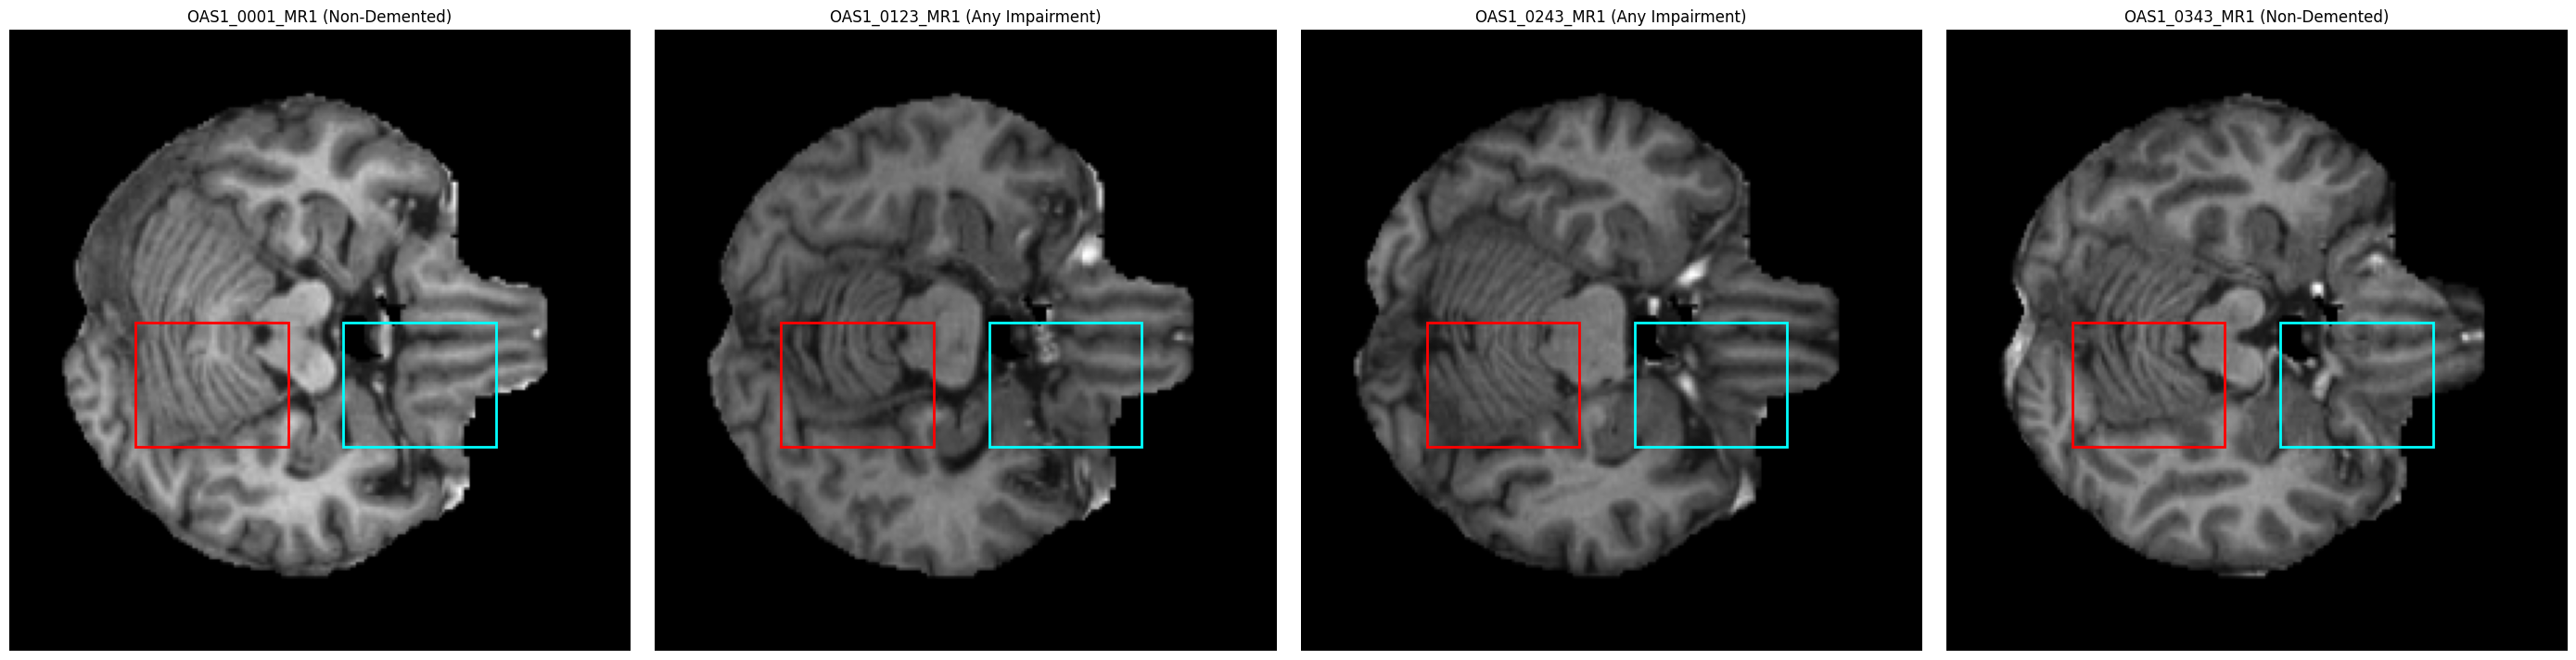

In [ ]:
# Slice 56 was located by visually scanning the volume: slice 88 (the
# atlas midpoint) turned out to be the ventricular body, not the
# hippocampus, and a wider search found the temporal lobe consistently
# visible in the 50-62 range. This checks the final centre and ROI boxes
# across four subjects spanning both classes, to confirm the placement
# generalises rather than being specific to one subject's anatomy.
NEW_CENTRE_SLICE = 56
roi_a = {'x': 45,  'y': 105, 'w': 55, 'h': 45}
roi_b = {'x': 120, 'y': 105, 'w': 55, 'h': 45}

sample_indices = [0, 50, 100, 150]
sample_rows = manifest.iloc[sample_indices]

fig, axes = plt.subplots(1, len(sample_rows), figsize=(7 * len(sample_rows), 7))
for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    vol = np.squeeze(nib.load(row['filepath']).get_fdata())
    sl = vol[:, :, NEW_CENTRE_SLICE]
    sl_norm = ((sl - sl.min()) / (sl.max() - sl.min() + 1e-8) * 255).astype(np.uint8)
    sl_resized = np.array(Image.fromarray(sl_norm).resize((224, 224)))
    ax.imshow(sl_resized, cmap='gray')
    for roi, color in [(roi_a, 'red'), (roi_b, 'cyan')]:
        rect = patches.Rectangle((roi['x'], roi['y']), roi['w'], roi['h'], linewidth=2, edgecolor=color, facecolor='none')
        ax.add_patch(rect)
    ax.set_title(f"{row['ID']} ({row['label']})")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
roi_a = {'x': 45, 'y': 105, 'w': 55, 'h': 45}
roi_b = {'x': 120, 'y': 105, 'w': 55, 'h': 45}

In [ ]:
# Print CustomCNN's layer names to confirm the actual final conv layer
# for Grad-CAM, rather than guessing.
custom_model_check = CustomCNN()
print(custom_model_check)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=512, out_features=2, bias=True)
  )
)


In [ ]:
import time

# Wall-clock training time, measured for one representative fold (fold 0)
# rather than a full 20-fold retrain, since timing doesn't need the same
# cross-validated treatment as the performance metrics.

training_times = {}

architectures = [
    ('ResNet50', build_resnet50),
    ('EfficientNetB4', build_efficientnet_b4),
    ('VGG16', build_vgg16),
    ('CustomCNN', CustomCNN),
]

fold = 0
outer_train_df = manifest[manifest['fold'] != fold].reset_index(drop=True)
inner_train_df, inner_val_df = train_test_split(
    outer_train_df, test_size=0.15,
    stratify=outer_train_df['label'], random_state=RANDOM_SEED,
)
inner_train_df = inner_train_df.reset_index(drop=True)
inner_val_df = inner_val_df.reset_index(drop=True)

train_dataset = OASISDataset(inner_train_df, transform=train_transform, slice_offsets=SLICE_OFFSETS)
inner_val_dataset = OASISDataset(inner_val_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2)
inner_val_loader = DataLoader(inner_val_dataset, batch_size=16, shuffle=False, num_workers=2)

for model_name, builder in architectures:
    print(f"\nTiming {model_name}...")
    start = time.time()

    model = builder().to(device)
    trained_model, _ = train_model(
        model, train_loader, inner_val_loader, class_weights,
        max_epochs=50, patience=5, lr=0.0001, phase_name=f"{model_name}-Timing-Phase1"
    )

    if model_name != 'CustomCNN':
        trained_model = unfreeze_for_phase2(trained_model, model_name)
        trained_model, _ = train_model(
            trained_model, train_loader, inner_val_loader, class_weights,
            max_epochs=20, patience=5, lr=1e-5, phase_name=f"{model_name}-Timing-Phase2"
        )

    elapsed = time.time() - start
    training_times[model_name] = elapsed
    print(f"  {model_name} total (Phase 1{'+ Phase 2' if model_name != 'CustomCNN' else ''}): {elapsed/60:.1f} minutes")

print("\n\nTraining times (fold 0, Phase 1 + Phase 2 where applicable):")
for name, t in training_times.items():
    print(f"  {name}: {t/60:.1f} min")

import json
with open('/content/drive/MyDrive/MSC PROJECT/training_times.json', 'w') as f:
    json.dump({k: v for k, v in training_times.items()}, f, indent=2)
print("\nSaved: training_times.json")


Timing ResNet50...
[ResNet50-Timing-Phase1] Epoch 1/50 | train_loss: 0.6847 | earlystop_loss: 0.6885 | earlystop_acc: 58.33% | earlystop_f1: 0.4958 | n_subjects (inner-val): 24
[ResNet50-Timing-Phase1] Epoch 2/50 | train_loss: 0.6699 | earlystop_loss: 0.6828 | earlystop_acc: 45.83% | earlystop_f1: 0.4497 | n_subjects (inner-val): 24
[ResNet50-Timing-Phase1] Epoch 3/50 | train_loss: 0.6532 | earlystop_loss: 0.6824 | earlystop_acc: 45.83% | earlystop_f1: 0.4497 | n_subjects (inner-val): 24
[ResNet50-Timing-Phase1] Epoch 4/50 | train_loss: 0.6357 | earlystop_loss: 0.6792 | earlystop_acc: 50.00% | earlystop_f1: 0.4965 | n_subjects (inner-val): 24
[ResNet50-Timing-Phase1] Epoch 5/50 | train_loss: 0.6178 | earlystop_loss: 0.6755 | earlystop_acc: 50.00% | earlystop_f1: 0.5000 | n_subjects (inner-val): 24
[ResNet50-Timing-Phase1] Epoch 6/50 | train_loss: 0.6125 | earlystop_loss: 0.6830 | earlystop_acc: 62.50% | earlystop_f1: 0.5901 | n_subjects (inner-val): 24
[ResNet50-Timing-Phase1] Epoch 7

In [ ]:

import torch.nn.functional as F
from collections import defaultdict
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

def get_gradcam_target_layer(model, model_name):
    if model_name == 'ResNet50':
        return [model.layer4[-1]]
    elif model_name == 'EfficientNetB4':
        return [model.features[8]]
    elif model_name == 'VGG16':
        return [model.features[28]]
    elif model_name == 'CustomCNN':
        return [model.features[9]]
    else:
        raise ValueError(f"Unknown model_name for Grad-CAM: {model_name}")

ROI_A = {'x': 45,  'y': 105, 'w': 55, 'h': 45}
ROI_B = {'x': 120, 'y': 105, 'w': 55, 'h': 45}

def roi_mask(shape=(224, 224)):
    mask = np.zeros(shape, dtype=bool)
    for roi in (ROI_A, ROI_B):
        mask[roi['y']:roi['y']+roi['h'], roi['x']:roi['x']+roi['w']] = True
    return mask

HIPPOCAMPAL_MASK = roi_mask()


def compute_gradcam_heatmap(model, model_name, image_tensor, target_class):
    target_layers = get_gradcam_target_layer(model, model_name)
    cam = GradCAM(model=model, target_layers=target_layers)
    targets = [ClassifierOutputTarget(target_class)]
    grayscale_cam = cam(input_tensor=image_tensor, targets=targets)
    return grayscale_cam[0]


def score_plausibility(heatmap, top_percentile=75):
    threshold_value = np.percentile(heatmap, top_percentile)
    thresholded = heatmap >= threshold_value
    total_active = thresholded.sum()
    if total_active == 0:
        return 0.0, 'anatomically implausible'
    overlap = (thresholded & HIPPOCAMPAL_MASK).sum()
    overlap_fraction = overlap / total_active
    if overlap_fraction >= 0.50:
        tier = 'anatomically plausible'
    elif overlap_fraction >= 0.20:
        tier = 'partially plausible'
    else:
        tier = 'anatomically implausible'
    return overlap_fraction, tier


def load_trained_model(model_name, fold, device):
    builders = {
        'ResNet50': build_resnet50,
        'EfficientNetB4': build_efficientnet_b4,
        'VGG16': build_vgg16,
        'CustomCNN': CustomCNN,
    }
    model = builders[model_name]().to(device)
    state_dict_path = f'/content/drive/MyDrive/MSC PROJECT/models/{model_name}_fold{fold}.pt'
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    for param in model.parameters():
        param.requires_grad = True
    model.eval()
    return model


def evaluate_gradcam_multislice_on_fold(model, model_name, test_loader, device):
    """
    Computes Grad-CAM across all seven slices per subject and averages the
    resulting heatmaps into one subject-level heatmap, mirroring exactly
    how the classification prediction itself is aggregated: average
    predicted probability across seven slices, then argmax (Section 3.6).

    Two passes are needed. First, every slice's prediction is collected
    per subject to compute the SAME subject-level predicted class used
    for the actual reported classification -- this is the Grad-CAM
    target class used for ALL SEVEN of that subject's slices, so all
    seven heatmaps explain the same target decision rather than
    potentially disagreeing slice-by-slice targets. Second, Grad-CAM is
    computed for each of the seven slices against that shared target,
    and the seven heatmaps are averaged pixel-wise into one subject-level
    heatmap, from which the overlap percentage is computed exactly as
    for the single-slice version.

    test_loader must be built with slice_offsets=SLICE_OFFSETS (all
    seven slices), not slice_offsets=(0,).
    """
    model.eval()

    # --- Pass 1: collect every slice's prediction, grouped by subject ---
    subject_probs = defaultdict(list)
    subject_labels = {}
    subject_images = defaultdict(list)  # kept on CPU between passes

    with torch.no_grad():
        for images_batch, labels_batch, subject_id_batch in test_loader:
            images_dev = images_batch.to(device)
            outputs = model(images_dev)
            probs = F.softmax(outputs, dim=1).cpu().numpy()
            for i in range(images_batch.size(0)):
                subj = subject_id_batch[i]
                subject_probs[subj].append(probs[i])
                subject_labels[subj] = int(labels_batch[i])
                subject_images[subj].append(images_batch[i])  # CPU tensor

    # --- Pass 2: Grad-CAM per slice, averaged to one subject-level heatmap ---
    results = []
    for subj, prob_list in subject_probs.items():
        mean_prob = np.mean(prob_list, axis=0)
        pred_class = int(np.argmax(mean_prob))
        true_class = subject_labels[subj]

        heatmaps = []
        for img_tensor in subject_images[subj]:
            single_image = img_tensor.unsqueeze(0).to(device)
            heatmap = compute_gradcam_heatmap(model, model_name, single_image, pred_class)
            heatmaps.append(heatmap)

        subject_heatmap = np.mean(heatmaps, axis=0)
        overlap_fraction, tier = score_plausibility(subject_heatmap)

        results.append({
            'subject_id': subj,
            'true_class': true_class,
            'predicted_class': pred_class,
            'correct': true_class == pred_class,
            'overlap_fraction': overlap_fraction,
            'plausibility_tier': tier,
            'n_slices_averaged': len(heatmaps),
        })

    return results


# =====================================================================
# Main evaluation loop -- note slice_offsets=SLICE_OFFSETS (all seven),
# not (0,) as in the earlier centre-slice-only version.
# =====================================================================

all_gradcam_results = []

for model_name in ['ResNet50', 'EfficientNetB4', 'VGG16', 'CustomCNN']:
    for fold in range(5):
        print(f"Running multi-slice Grad-CAM: {model_name} fold {fold}...")

        outer_test_df = manifest[manifest['fold'] == fold].reset_index(drop=True)
        outer_test_dataset = OASISDataset(outer_test_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)
        outer_test_loader = DataLoader(outer_test_dataset, batch_size=16, shuffle=False, num_workers=2)

        model = load_trained_model(model_name, fold, device)
        fold_results = evaluate_gradcam_multislice_on_fold(model, model_name, outer_test_loader, device)

        for r in fold_results:
            r['model'] = model_name
            r['fold'] = fold
        all_gradcam_results.extend(fold_results)

        del model
        torch.cuda.empty_cache()

        print(f"  {len(fold_results)} subjects processed (7 slices each, averaged)")

gradcam_df = pd.DataFrame(all_gradcam_results)
gradcam_df.to_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_results_multislice.csv', index=False)
print(f"\nSaved {len(gradcam_df)} subject-level Grad-CAM results to gradcam_results_multislice.csv")

print("\nMean overlap percentage by model:")
print(gradcam_df.groupby('model')['overlap_fraction'].agg(['mean', 'std', 'count']))

print("\nPlausibility tier distribution by model:")
print(gradcam_df.groupby(['model', 'plausibility_tier']).size().unstack(fill_value=0))

print("\nMean overlap percentage, correct vs incorrect predictions:")
print(gradcam_df.groupby(['model', 'correct'])['overlap_fraction'].agg(['mean', 'std', 'count']))

Running multi-slice Grad-CAM: ResNet50 fold 0...
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 140MB/s]


  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: ResNet50 fold 1...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: ResNet50 fold 2...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: ResNet50 fold 3...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: ResNet50 fold 4...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: EfficientNetB4 fold 0...
Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 192MB/s]


  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: EfficientNetB4 fold 1...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: EfficientNetB4 fold 2...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: EfficientNetB4 fold 3...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: EfficientNetB4 fold 4...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: VGG16 fold 0...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 63.5MB/s]


  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: VGG16 fold 1...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: VGG16 fold 2...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: VGG16 fold 3...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: VGG16 fold 4...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: CustomCNN fold 0...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: CustomCNN fold 1...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: CustomCNN fold 2...
  40 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: CustomCNN fold 3...
  39 subjects processed (7 slices each, averaged)
Running multi-slice Grad-CAM: CustomCNN fold 4...
  39 subjects processed (7 slices each, averaged)

Saved 792 subject-level Grad-CAM results to gradcam_results_multi

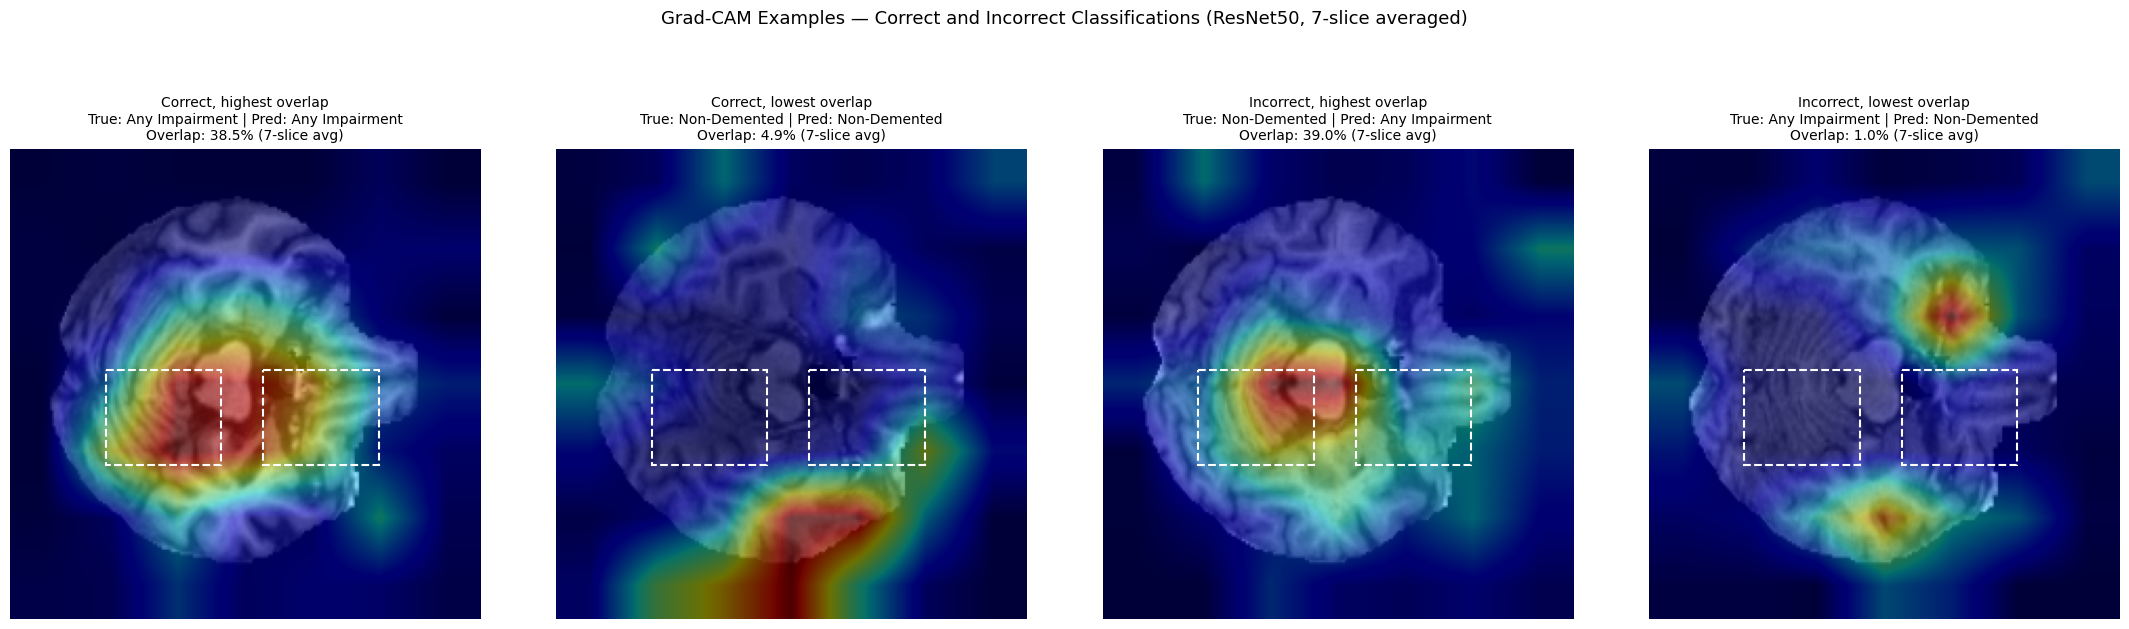

Saved: gradcam_examples_multislice.png


In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
# get_gradcam_target_layer, compute_gradcam_heatmap, and load_trained_model
# are already defined above; ROI_A/ROI_B are already defined above too.


# =====================================================================
# Select 4 representative cases from the REAL multi-slice results CSV,
# same rule as before: highest/lowest overlap among correct/incorrect
# ResNet50 predictions -- selected by rule, not by appearance.
# =====================================================================

gradcam_df = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_results_multislice.csv')
resnet_df = gradcam_df[gradcam_df['model'] == 'ResNet50'].copy()

correct_df = resnet_df[resnet_df['correct'] == True]
incorrect_df = resnet_df[resnet_df['correct'] == False]

cases = {
    'Correct, highest overlap': correct_df.loc[correct_df['overlap_fraction'].idxmax()],
    'Correct, lowest overlap': correct_df.loc[correct_df['overlap_fraction'].idxmin()],
    'Incorrect, highest overlap': incorrect_df.loc[incorrect_df['overlap_fraction'].idxmax()],
    'Incorrect, lowest overlap': incorrect_df.loc[incorrect_df['overlap_fraction'].idxmin()],
}

label_names = {0: 'Non-Demented', 1: 'Any Impairment'}

fig, axes = plt.subplots(1, 4, figsize=(22, 6))

for ax, (case_title, row) in zip(axes, cases.items()):
    subject_id = row['subject_id']
    fold = int(row['fold'])
    pred_class = int(row['predicted_class'])

    subject_row = manifest[manifest['ID'] == subject_id].iloc[0]
    volume = np.squeeze(nib.load(subject_row['filepath']).get_fdata())

    model = load_trained_model('ResNet50', fold, device)

    # Recompute the same seven-slice-averaged heatmap this subject's
    # overlap_fraction was actually derived from, using the SAME target
    # class (the subject-level prediction) for all seven slices.
    heatmaps = []
    centre_slice_rgb = None
    for offset in SLICE_OFFSETS:
        idx = 56 + offset
        sl = volume[:, :, idx]
        sl_norm = ((sl - sl.min()) / (sl.max() - sl.min() + 1e-8) * 255).astype(np.uint8)
        sl_rgb = np.stack([sl_norm]*3, axis=-1)
        sl_resized = np.array(Image.fromarray(sl_rgb).resize((224, 224)))
        if offset == 0:
            centre_slice_rgb = sl_resized

        transformed = val_transform(image=sl_resized)['image'].unsqueeze(0).to(device)
        heatmap = compute_gradcam_heatmap(model, 'ResNet50', transformed, pred_class)
        heatmaps.append(heatmap)

    subject_heatmap = np.mean(heatmaps, axis=0)

    del model
    torch.cuda.empty_cache()

    ax.imshow(centre_slice_rgb)
    ax.imshow(subject_heatmap, cmap='jet', alpha=0.45)
    for roi, color in [(ROI_A, 'white'), (ROI_B, 'white')]:
        rect = patches.Rectangle((roi['x'], roi['y']), roi['w'], roi['h'],
                                   linewidth=1.5, edgecolor=color, facecolor='none', linestyle='--')
        ax.add_patch(rect)

    true_lbl = label_names[row['true_class']]
    pred_lbl = label_names[pred_class]
    ax.set_title(f"{case_title}\nTrue: {true_lbl} | Pred: {pred_lbl}\nOverlap: {row['overlap_fraction']:.1%} (7-slice avg)", fontsize=10)
    ax.axis('off')

plt.suptitle("Grad-CAM Examples — Correct and Incorrect Classifications (ResNet50, 7-slice averaged)", fontsize=13, y=1.04)
plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.savefig('/content/drive/MyDrive/MSC PROJECT/gradcam_examples_multislice.png', dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: gradcam_examples_multislice.png")

In [ ]:

from sklearn.metrics import f1_score, recall_score

gradcam_df = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_results_multislice.csv')

N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

def accuracy_fn(y_true, y_pred):
    return (y_true == y_pred).mean()

def macro_f1_fn(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro', zero_division=0)

def sensitivity_fn(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=1, zero_division=0)

def specificity_fn(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=0, zero_division=0)

def bootstrap_ci(true, pred, metric_fn, n_bootstrap=N_BOOTSTRAP):
    n = len(true)
    boot_stats = np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        idx = rng.integers(0, n, n)
        boot_stats[i] = metric_fn(true[idx], pred[idx])
    return boot_stats.mean(), np.percentile(boot_stats, 2.5), np.percentile(boot_stats, 97.5)

results = []
metrics = [('Accuracy', accuracy_fn), ('Macro-F1', macro_f1_fn),
           ('Sensitivity', sensitivity_fn), ('Specificity', specificity_fn)]

for model_name in ['ResNet50', 'EfficientNetB4', 'VGG16', 'CustomCNN']:
    model_df = gradcam_df[gradcam_df['model'] == model_name]
    true = model_df['true_class'].values
    pred = model_df['predicted_class'].values

    print(f"\n{model_name} (n={len(model_df)} subjects):")
    for metric_name, metric_fn in metrics:
        mean_val, ci_low, ci_high = bootstrap_ci(true, pred, metric_fn)
        results.append({'model': model_name, 'metric': metric_name,
                         'mean': mean_val, 'ci_low': ci_low, 'ci_high': ci_high})
        print(f"  {metric_name}: {mean_val:.4f} (95% CI: {ci_low:.4f} – {ci_high:.4f})")

print("\nNote: ROC-AUC is not included -- this bootstrap uses hard predicted")
print("classes from the saved Grad-CAM results file, which does not include")
print("predicted probabilities needed for a threshold-varying AUC bootstrap.")

results_df = pd.DataFrame(results)
results_df.to_csv('/content/drive/MyDrive/MSC PROJECT/bootstrap_ci_results.csv', index=False)
print("\nSaved: bootstrap_ci_results.csv")


ResNet50 (n=198 subjects):
  Accuracy: 0.6408 (95% CI: 0.5707 – 0.7071)
  Macro-F1: 0.6367 (95% CI: 0.5688 – 0.7027)
  Sensitivity: 0.5496 (95% CI: 0.4505 – 0.6458)
  Specificity: 0.7353 (95% CI: 0.6471 – 0.8218)

EfficientNetB4 (n=198 subjects):
  Accuracy: 0.6414 (95% CI: 0.5758 – 0.7071)
  Macro-F1: 0.6401 (95% CI: 0.5707 – 0.7070)
  Sensitivity: 0.6400 (95% CI: 0.5455 – 0.7327)
  Specificity: 0.6428 (95% CI: 0.5444 – 0.7368)

VGG16 (n=198 subjects):
  Accuracy: 0.6667 (95% CI: 0.6010 – 0.7323)
  Macro-F1: 0.6624 (95% CI: 0.5945 – 0.7270)
  Sensitivity: 0.5700 (95% CI: 0.4712 – 0.6667)
  Specificity: 0.7655 (95% CI: 0.6778 – 0.8462)

CustomCNN (n=198 subjects):
  Accuracy: 0.7169 (95% CI: 0.6515 – 0.7778)
  Macro-F1: 0.7154 (95% CI: 0.6530 – 0.7770)
  Sensitivity: 0.7703 (95% CI: 0.6860 – 0.8495)
  Specificity: 0.6632 (95% CI: 0.5696 – 0.7528)

Note: ROC-AUC is not included -- this bootstrap uses hard predicted
classes from the saved Grad-CAM results file, which does not include
pr

In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, recall_score

manifest = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/manifest_binary_folds.csv')
demographics_path = '/content/drive/MyDrive/MSC PROJECT/oasis_cross-sectional-5708aa0a98d82080.xlsx'
demo = pd.read_excel(demographics_path)

merged = manifest.merge(demo[['ID', 'Age', 'M/F']], on='ID', how='left')
merged['sex_encoded'] = (merged['M/F'] == 'M').astype(int)
merged['label_encoded'] = (merged['label'] == 'Any Impairment').astype(int)

baseline_results = []

for fold in range(5):
    train_df = merged[merged['fold'] != fold]
    test_df = merged[merged['fold'] == fold]

    X_train = train_df[['Age', 'sex_encoded']].values
    y_train = train_df['label_encoded'].values
    X_test = test_df[['Age', 'sex_encoded']].values
    y_test = test_df['label_encoded'].values

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    clf = LogisticRegression(random_state=42)
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)
    sens = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    spec = recall_score(y_test, y_pred, pos_label=0, zero_division=0)

    baseline_results.append({'fold': fold, 'accuracy': acc, 'macro_f1': f1,
                              'sensitivity': sens, 'specificity': spec, 'n_test': len(test_df)})
    print(f"Fold {fold}: acc={acc:.2%}, macro_f1={f1:.4f}, sens={sens:.4f}, spec={spec:.4f}, n={len(test_df)}")

baseline_df = pd.DataFrame(baseline_results)
print("\nMean ± SD across folds (age + sex only, logistic regression):")
print(f"Accuracy:    {baseline_df['accuracy'].mean():.2%} ± {baseline_df['accuracy'].std():.2%}")
print(f"Macro-F1:    {baseline_df['macro_f1'].mean():.4f} ± {baseline_df['macro_f1'].std():.4f}")
print(f"Sensitivity: {baseline_df['sensitivity'].mean():.4f} ± {baseline_df['sensitivity'].std():.4f}")
print(f"Specificity: {baseline_df['specificity'].mean():.4f} ± {baseline_df['specificity'].std():.4f}")

baseline_df.to_csv('/content/drive/MyDrive/MSC PROJECT/demographic_baseline_results.csv', index=False)
print("\nSaved: demographic_baseline_results.csv")

Fold 0: acc=50.00%, macro_f1=0.4987, sens=0.4500, spec=0.5500, n=40
Fold 1: acc=45.00%, macro_f1=0.4486, sens=0.5000, spec=0.4000, n=40
Fold 2: acc=55.00%, macro_f1=0.5312, sens=0.3500, spec=0.7500, n=40
Fold 3: acc=56.41%, macro_f1=0.5535, sens=0.4000, spec=0.7368, n=39
Fold 4: acc=64.10%, macro_f1=0.6389, sens=0.5500, spec=0.7368, n=39

Mean ± SD across folds (age + sex only, logistic regression):
Accuracy:    54.10% ± 7.17%
Macro-F1:    0.5342 ± 0.0706
Sensitivity: 0.4500 ± 0.0791
Specificity: 0.6347 ± 0.1553

Saved: demographic_baseline_results.csv


In [ ]:
from itertools import combinations

# Uses the already-saved multi-slice Grad-CAM results file. Pivoting to
# subject x model ensures every model's accuracy is computed on EXACTLY
# the same resampled set of subjects in each bootstrap iteration -- this
# is what makes it a PAIRED bootstrap rather than two independent ones:
# it preserves the fact that all four models were evaluated on the same
# 198 subjects, rather than treating each model's resample as unrelated
# to the others.
gradcam_df = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_results_multislice.csv')

pivot_correct = gradcam_df.pivot(index='subject_id', columns='model', values='correct').astype(float)
pivot_true = gradcam_df.pivot(index='subject_id', columns='model', values='true_class')

# Sanity check: every model should agree on each subject's true label
assert (pivot_true.nunique(axis=1) == 1).all(), "Mismatched true labels across models for some subject"

models = ['ResNet50', 'EfficientNetB4', 'VGG16', 'CustomCNN']
n_subjects = len(pivot_correct)
N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

def paired_bootstrap_diff(model_a, model_b, n_bootstrap=N_BOOTSTRAP):
    acc_a = pivot_correct[model_a].values
    acc_b = pivot_correct[model_b].values
    diffs = np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        idx = rng.integers(0, n_subjects, n_subjects)  # SAME resample for both models
        diffs[i] = acc_a[idx].mean() - acc_b[idx].mean()
    return diffs

results = []
print(f"Paired bootstrap comparison of accuracy, {N_BOOTSTRAP} resamples, n={n_subjects} subjects:\n")

for model_a, model_b in combinations(models, 2):
    diffs = paired_bootstrap_diff(model_a, model_b)
    mean_diff = diffs.mean()
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    excludes_zero = (ci_low > 0) or (ci_high < 0)
    results.append({
        'comparison': f'{model_a} vs {model_b}',
        'mean_diff_accuracy': mean_diff,
        'ci_low': ci_low,
        'ci_high': ci_high,
        'ci_excludes_zero': excludes_zero,
    })
    sig = "significant (95% CI excludes 0)" if excludes_zero else "not significant (95% CI includes 0)"
    print(f"{model_a} vs {model_b}: diff = {mean_diff:+.4f} (95% CI: {ci_low:+.4f} to {ci_high:+.4f}) -- {sig}")

results_df = pd.DataFrame(results)
results_df.to_csv('/content/drive/MyDrive/MSC PROJECT/paired_bootstrap_results.csv', index=False)
print("\nSaved: paired_bootstrap_results.csv")

Paired bootstrap comparison of accuracy, 10000 resamples, n=198 subjects:

ResNet50 vs EfficientNetB4: diff = -0.0001 (95% CI: -0.0707 to +0.0707) -- not significant (95% CI includes 0)
ResNet50 vs VGG16: diff = -0.0256 (95% CI: -0.0909 to +0.0404) -- not significant (95% CI includes 0)
ResNet50 vs CustomCNN: diff = -0.0758 (95% CI: -0.1465 to -0.0051) -- significant (95% CI excludes 0)
EfficientNetB4 vs VGG16: diff = -0.0248 (95% CI: -0.0960 to +0.0455) -- not significant (95% CI includes 0)
EfficientNetB4 vs CustomCNN: diff = -0.0755 (95% CI: -0.1465 to -0.0051) -- significant (95% CI excludes 0)
VGG16 vs CustomCNN: diff = -0.0508 (95% CI: -0.1162 to +0.0152) -- not significant (95% CI includes 0)

Saved: paired_bootstrap_results.csv


In [ ]:
# Reuses the same multi-slice Grad-CAM results file the accuracy bootstrap
# already reads -- no new computation needed, just a different column
# (overlap_fraction instead of correct/predicted_class).
gradcam_df = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_results_multislice.csv')

N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

# =====================================================================
# Part 1: Bootstrap CI for mean overlap percentage, per model
# =====================================================================

print(f"95% bootstrap CIs for mean Grad-CAM overlap, {N_BOOTSTRAP} resamples:\n")

overlap_ci_results = []
for model_name in ['ResNet50', 'EfficientNetB4', 'VGG16', 'CustomCNN']:
    values = gradcam_df[gradcam_df['model'] == model_name]['overlap_fraction'].values
    n = len(values)
    boot_means = np.empty(N_BOOTSTRAP)
    for i in range(N_BOOTSTRAP):
        idx = rng.integers(0, n, n)
        boot_means[i] = values[idx].mean()
    mean_val = boot_means.mean()
    ci_low, ci_high = np.percentile(boot_means, [2.5, 97.5])
    overlap_ci_results.append({'model': model_name, 'mean_overlap': mean_val,
                                'ci_low': ci_low, 'ci_high': ci_high, 'n': n})
    print(f"{model_name}: {mean_val:.4f} (95% CI: {ci_low:.4f} \u2013 {ci_high:.4f}), n={n}")

pd.DataFrame(overlap_ci_results).to_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_overlap_ci_results.csv', index=False)
print("\nSaved: gradcam_overlap_ci_results.csv")

# =====================================================================
# Part 2: Paired bootstrap of overlap-percentage DIFFERENCE between
# every pair of architectures, using the same resampled subjects for
# both models in each iteration -- preserves pairing, same principle as
# the accuracy paired bootstrap.
# =====================================================================

pivot_overlap = gradcam_df.pivot(index='subject_id', columns='model', values='overlap_fraction')
n_subjects = len(pivot_overlap)
models = ['ResNet50', 'EfficientNetB4', 'VGG16', 'CustomCNN']

def paired_bootstrap_overlap_diff(model_a, model_b, n_bootstrap=N_BOOTSTRAP):
    vals_a = pivot_overlap[model_a].values
    vals_b = pivot_overlap[model_b].values
    diffs = np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        idx = rng.integers(0, n_subjects, n_subjects)
        diffs[i] = vals_a[idx].mean() - vals_b[idx].mean()
    return diffs

print(f"\nPaired bootstrap comparison of mean overlap percentage, n={n_subjects} subjects:\n")

paired_results = []
for model_a, model_b in combinations(models, 2):
    diffs = paired_bootstrap_overlap_diff(model_a, model_b)
    mean_diff = diffs.mean()
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    excludes_zero = (ci_low > 0) or (ci_high < 0)
    paired_results.append({'comparison': f'{model_a} vs {model_b}', 'mean_diff_overlap': mean_diff,
                            'ci_low': ci_low, 'ci_high': ci_high, 'ci_excludes_zero': excludes_zero})
    sig = "significant (95% CI excludes 0)" if excludes_zero else "not significant (95% CI includes 0)"
    print(f"{model_a} vs {model_b}: diff = {mean_diff:+.4f} (95% CI: {ci_low:+.4f} to {ci_high:+.4f}) -- {sig}")

pd.DataFrame(paired_results).to_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_paired_bootstrap_results.csv', index=False)
print("\nSaved: gradcam_paired_bootstrap_results.csv")


95% bootstrap CIs for mean Grad-CAM overlap, 10000 resamples:

ResNet50: 0.2242 (95% CI: 0.2129 – 0.2358), n=198
EfficientNetB4: 0.1653 (95% CI: 0.1527 – 0.1779), n=198
VGG16: 0.1615 (95% CI: 0.1424 – 0.1810), n=198
CustomCNN: 0.1287 (95% CI: 0.1196 – 0.1378), n=198

Saved: gradcam_overlap_ci_results.csv

Paired bootstrap comparison of mean overlap percentage, n=198 subjects:

ResNet50 vs EfficientNetB4: diff = +0.0590 (95% CI: +0.0400 to +0.0785) -- significant (95% CI excludes 0)
ResNet50 vs VGG16: diff = +0.0626 (95% CI: +0.0429 to +0.0822) -- significant (95% CI excludes 0)
ResNet50 vs CustomCNN: diff = +0.0956 (95% CI: +0.0812 to +0.1098) -- significant (95% CI excludes 0)
EfficientNetB4 vs VGG16: diff = +0.0036 (95% CI: -0.0223 to +0.0293) -- not significant (95% CI includes 0)
EfficientNetB4 vs CustomCNN: diff = +0.0367 (95% CI: +0.0207 to +0.0525) -- significant (95% CI excludes 0)
VGG16 vs CustomCNN: diff = +0.0330 (95% CI: +0.0123 to +0.0537) -- significant (95% CI excludes 0

In [ ]:

# Recomputes the six Grad-CAM overlap paired-bootstrap comparisons, this
# time estimating an actual two-sided bootstrap p-value for each (not
# just whether the 95% CI excludes zero), then applying Holm-Bonferroni
# correction across all six -- a proper family-wise correction, not an
# approximation.
gradcam_df = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_results_multislice.csv')

N_BOOTSTRAP = 10000
rng = np.random.default_rng(42)

pivot_overlap = gradcam_df.pivot(index='subject_id', columns='model', values='overlap_fraction')
n_subjects = len(pivot_overlap)
models = ['ResNet50', 'EfficientNetB4', 'VGG16', 'CustomCNN']

def paired_bootstrap_pvalue(model_a, model_b, n_bootstrap=N_BOOTSTRAP):
    vals_a = pivot_overlap[model_a].values
    vals_b = pivot_overlap[model_b].values
    diffs = np.empty(n_bootstrap)
    for i in range(n_bootstrap):
        idx = rng.integers(0, n_subjects, n_subjects)
        diffs[i] = vals_a[idx].mean() - vals_b[idx].mean()
    observed_diff = vals_a.mean() - vals_b.mean()
    # Two-sided bootstrap p-value: proportion of resamples on the
    # opposite side of zero from the observed difference, doubled.
    if observed_diff >= 0:
        p = 2 * (diffs <= 0).mean()
    else:
        p = 2 * (diffs >= 0).mean()
    p = min(p, 1.0)
    ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
    return observed_diff, p, ci_low, ci_high

results = []
for model_a, model_b in combinations(models, 2):
    diff, p, ci_low, ci_high = paired_bootstrap_pvalue(model_a, model_b)
    results.append({'comparison': f'{model_a} vs {model_b}', 'diff': diff, 'p_value': p,
                     'ci_low': ci_low, 'ci_high': ci_high})

# Holm-Bonferroni: sort p-values ascending, compare each to
# alpha / (m - rank + 1), stop at the first failure.
alpha = 0.05
m = len(results)
results_sorted = sorted(results, key=lambda r: r['p_value'])
for rank, r in enumerate(results_sorted, start=1):
    threshold = alpha / (m - rank + 1)
    r['holm_threshold'] = threshold
    r['holm_significant'] = r['p_value'] < threshold

# Once a comparison fails, all later (larger p-value) ones are also
# non-significant under Holm-Bonferroni's step-down procedure.
failed = False
for r in results_sorted:
    if failed:
        r['holm_significant'] = False
    elif not r['holm_significant']:
        failed = True

print(f"Holm-Bonferroni corrected results ({m} comparisons, family-wise alpha={alpha}):\n")
for r in results_sorted:
    sig = "SIGNIFICANT after correction" if r['holm_significant'] else "not significant after correction"
    print(f"{r['comparison']}: diff={r['diff']:+.4f}, p={r['p_value']:.4f}, "
          f"Holm threshold={r['holm_threshold']:.4f} -- {sig}")

pd.DataFrame(results_sorted).to_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_holm_bonferroni_results.csv', index=False)
print("\nSaved: gradcam_holm_bonferroni_results.csv")


Holm-Bonferroni corrected results (6 comparisons, family-wise alpha=0.05):

ResNet50 vs EfficientNetB4: diff=+0.0589, p=0.0000, Holm threshold=0.0083 -- SIGNIFICANT after correction
ResNet50 vs VGG16: diff=+0.0627, p=0.0000, Holm threshold=0.0100 -- SIGNIFICANT after correction
ResNet50 vs CustomCNN: diff=+0.0956, p=0.0000, Holm threshold=0.0125 -- SIGNIFICANT after correction
EfficientNetB4 vs CustomCNN: diff=+0.0367, p=0.0000, Holm threshold=0.0167 -- SIGNIFICANT after correction
VGG16 vs CustomCNN: diff=+0.0329, p=0.0022, Holm threshold=0.0250 -- SIGNIFICANT after correction
EfficientNetB4 vs VGG16: diff=+0.0038, p=0.7702, Holm threshold=0.0500 -- not significant after correction

Saved: gradcam_holm_bonferroni_results.csv


In [ ]:
from collections import defaultdict
from sklearn.metrics import confusion_matrix

# Re-runs inference only (no retraining) using the saved fold checkpoints,
# aggregates true/predicted labels across all five folds per architecture,
# and computes the confusion matrix each already-reported sensitivity/
# specificity figure was derived from.
manifest = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/manifest_binary_folds.csv')
model_builders = {
    'ResNet50': build_resnet50,
    'EfficientNetB4': build_efficientnet_b4,
    'VGG16': build_vgg16,
    'CustomCNN': CustomCNN,
}

results = {}
for model_name, builder_fn in model_builders.items():
    all_true, all_pred = [], []
    for fold in range(N_FOLDS):
        # Assumes checkpoints are saved as "{model_name}_fold{fold}.pt" in
        # this folder, matching the training loop's own save convention --
        # check this path if the load fails.
        checkpoint_path = f'/content/drive/MyDrive/MSC PROJECT/models/{model_name}_fold{fold}.pt'
        model = builder_fn()
        model.load_state_dict(torch.load(checkpoint_path, map_location=device))
        model = model.to(device)
        model.eval()

        test_df = manifest[manifest['fold'] == fold]
        test_dataset = OASISDataset(test_df, transform=val_transform, slice_offsets=SLICE_OFFSETS)
        test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

        subject_probs = defaultdict(list)
        subject_labels = {}
        with torch.no_grad():
            for images_batch, labels_batch, subject_id_batch in test_loader:
                images_batch = images_batch.to(device)
                outputs = model(images_batch)
                probs = F.softmax(outputs, dim=1).cpu().numpy()
                for prob, label, subj in zip(probs, labels_batch.numpy(), subject_id_batch):
                    subject_probs[subj].append(prob)
                    subject_labels[subj] = label

        for subj in subject_probs:
            mean_prob = np.mean(subject_probs[subj], axis=0)
            all_pred.append(int(np.argmax(mean_prob)))
            all_true.append(int(subject_labels[subj]))

    cm = confusion_matrix(all_true, all_pred, labels=[0, 1])
    results[model_name] = cm
    print(f"\n{model_name} confusion matrix (n={len(all_true)} subjects, aggregated across all 5 folds):")
    print(f"  True Non-Demented,    Pred Non-Demented: {cm[0][0]}, Pred Any Impairment: {cm[0][1]}")
    print(f"  True Any Impairment,  Pred Non-Demented: {cm[1][0]}, Pred Any Impairment: {cm[1][1]}")

rows = []
for model_name, cm in results.items():
    rows.append({'Model': model_name, 'True class': 'Non-Demented',
                 'Predicted Non-Demented': cm[0][0], 'Predicted Any Impairment': cm[0][1]})
    rows.append({'Model': model_name, 'True class': 'Any Impairment',
                 'Predicted Non-Demented': cm[1][0], 'Predicted Any Impairment': cm[1][1]})
pd.DataFrame(rows).to_csv('/content/drive/MyDrive/MSC PROJECT/confusion_matrices.csv', index=False)
print("\nSaved: confusion_matrices.csv")



ResNet50 confusion matrix (n=198 subjects, aggregated across all 5 folds):
  True Non-Demented,    Pred Non-Demented: 72, Pred Any Impairment: 26
  True Any Impairment,  Pred Non-Demented: 45, Pred Any Impairment: 55

EfficientNetB4 confusion matrix (n=198 subjects, aggregated across all 5 folds):
  True Non-Demented,    Pred Non-Demented: 63, Pred Any Impairment: 35
  True Any Impairment,  Pred Non-Demented: 36, Pred Any Impairment: 64

VGG16 confusion matrix (n=198 subjects, aggregated across all 5 folds):
  True Non-Demented,    Pred Non-Demented: 75, Pred Any Impairment: 23
  True Any Impairment,  Pred Non-Demented: 43, Pred Any Impairment: 57

CustomCNN confusion matrix (n=198 subjects, aggregated across all 5 folds):
  True Non-Demented,    Pred Non-Demented: 65, Pred Any Impairment: 33
  True Any Impairment,  Pred Non-Demented: 23, Pred Any Impairment: 77

Saved: confusion_matrices.csv


Unique values in 'metric' column: ['Accuracy', 'Macro-F1', 'Sensitivity', 'Specificity']


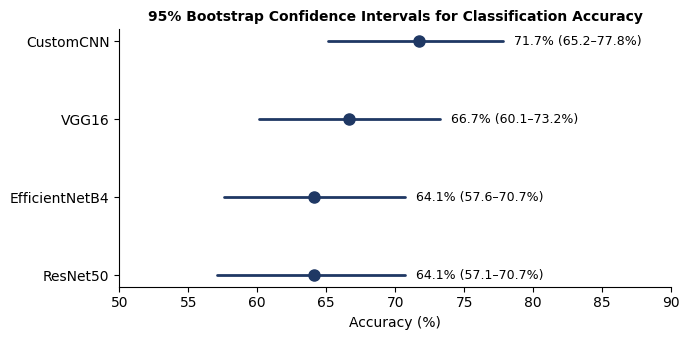

Saved: forest_plot_accuracy.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Reads directly from the saved bootstrap CI results, so this always
# reflects the latest training run rather than hardcoded numbers.
# The CSV is in long format: one row per (model, metric) combination.
df_all = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/bootstrap_ci_results.csv')
print("Unique values in 'metric' column:", df_all['metric'].unique().tolist())

# Case-insensitive, substring match rather than an exact string, since
# the exact label used ('accuracy' vs 'Accuracy' vs 'acc') isn't certain.
df = df_all[df_all['metric'].astype(str).str.lower().str.contains('accuracy|^acc$', regex=True, na=False)].copy()

if df.empty:
    raise ValueError(
        f"No rows matched an accuracy-like metric. "
        f"Unique metric values found were: {df_all['metric'].unique().tolist()}. "
        f"Update the filter above to match whichever of these represents accuracy."
    )

df = df.sort_values('mean', ascending=False).reset_index(drop=True)

models = df['model'].tolist()
means = (df['mean'] * 100).tolist()
ci_low = (df['ci_low'] * 100).tolist()
ci_high = (df['ci_high'] * 100).tolist()

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (m, lo, hi) in enumerate(zip(means, ci_low, ci_high)):
    ax.plot([lo, hi], [i, i], color='#1F3864', linewidth=2, solid_capstyle='round')
    ax.plot(m, i, 'o', color='#1F3864', markersize=8, zorder=3)
    ax.text(hi + 0.8, i, f'{m:.1f}% ({lo:.1f}\u2013{hi:.1f}%)', va='center', fontsize=9)

ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=10)
ax.set_xlabel('Accuracy (%)', fontsize=10)
ax.set_xlim(50, 90)
ax.set_title('95% Bootstrap Confidence Intervals for Classification Accuracy', fontsize=10, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/MSC PROJECT/forest_plot_accuracy.png', dpi=200, facecolor='white')
plt.show()
print("Saved: forest_plot_accuracy.png")


Columns found in gradcam_overlap_ci_results.csv: ['model', 'mean_overlap', 'ci_low', 'ci_high', 'n']


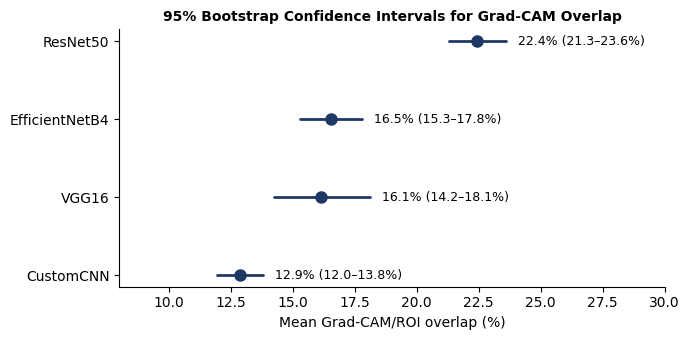

Saved: forest_plot_gradcam.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Same approach as the accuracy plot above, reading from the saved
# Grad-CAM overlap bootstrap CI results.
df = pd.read_csv('/content/drive/MyDrive/MSC PROJECT/gradcam_overlap_ci_results.csv')
print("Columns found in gradcam_overlap_ci_results.csv:", df.columns.tolist())

def find_column(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    raise KeyError(f"None of {candidates} found in columns: {df.columns.tolist()}")

model_col = find_column(df, ['model', 'Model', 'architecture'])
mean_col = find_column(df, ['mean_overlap', 'mean', 'overlap_mean', 'mean_overlap_fraction'])
lo_col = find_column(df, ['ci_low', 'overlap_ci_low', 'lower', 'ci_lower'])
hi_col = find_column(df, ['ci_high', 'overlap_ci_high', 'upper', 'ci_upper'])

# If this CSV is also in long format (one row per model+metric), filter
# to the overlap rows first, same as the accuracy plot needed.
if 'metric' in df.columns:
    df = df[df['metric'].str.contains('overlap', case=False, na=False)].copy()

df = df.sort_values(mean_col, ascending=False).reset_index(drop=True)

models = df[model_col].tolist()
means = (df[mean_col] * 100).tolist()
ci_low = (df[lo_col] * 100).tolist()
ci_high = (df[hi_col] * 100).tolist()

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (m, lo, hi) in enumerate(zip(means, ci_low, ci_high)):
    ax.plot([lo, hi], [i, i], color='#1F3864', linewidth=2, solid_capstyle='round')
    ax.plot(m, i, 'o', color='#1F3864', markersize=8, zorder=3)
    ax.text(hi + 0.5, i, f'{m:.1f}% ({lo:.1f}\u2013{hi:.1f}%)', va='center', fontsize=9)

ax.set_yticks(range(len(models)))
ax.set_yticklabels(models, fontsize=10)
ax.set_xlabel('Mean Grad-CAM/ROI overlap (%)', fontsize=10)
ax.set_xlim(8, 30)
ax.set_title('95% Bootstrap Confidence Intervals for Grad-CAM Overlap', fontsize=10, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/MSC PROJECT/forest_plot_gradcam.png', dpi=200, facecolor='white')
plt.show()
print("Saved: forest_plot_gradcam.png")
